# Изкуственият интелект в естетиката: система за препоръчване на козметични продукти според съставките и типа кожа

In [1]:
# -*- coding: utf-8 -*-
"""
Курсова работа по „Изкуствен интелект“:
Изкуственият интелект в естетиката: интелигентна система за
препоръчване на козметични продукти според съставките и типа кожа

Данни: Cosmetics Dataset (Kaggle) - 1 472 козметични продукта от Sephora
с пълен списък на съставките, цена, рейтинг и подходящ тип кожа.

Какво прави програмата:
  1. Почиства и анализира данните
  2. Открива кои съставки са по-рядко в продукти за чувствителна кожа
  3. Превръща списъка със съставки в числа (TF-IDF) и изчислява
     колко си приличат два продукта (косинусово сходство)
  4. Чертае „карта“ на продуктите с алгоритъма t-SNE
  5. Препоръчва сходни (и по-евтини) продукти за избран тип кожа
  6. Оценява колко добри са препоръките

Как се пуска:
  - Google Colab: копирай кода в клетка и натисни Run
  - Локално: pip install pandas matplotlib seaborn scikit-learn
"""

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity, pairwise_distances
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE

## 1. Зареждане на данните

In [2]:
# ---------------------------------------------------------------
# 1. Зареждане на данните
# ---------------------------------------------------------------
URL = ("https://raw.githubusercontent.com/veeralakrishna/"
       "DataCamp-Project-Solutions-Python/master/"
       "Comparing%20Cosmetics%20by%20Ingredients/datasets/cosmetics.csv")
df = pd.read_csv(URL)

print("Брой продукти и колони:", df.shape)
print("Брой марки:", df["Brand"].nunique())

kategorii = {"Moisturizer": "Овлажнител", "Cleanser": "Почистващ продукт",
             "Face Mask": "Маска за лице", "Treatment": "Серум/третиращ",
             "Eye cream": "Околоочен крем", "Sun protect": "Слънцезащитен"}
df["категория"] = df["Label"].map(kategorii)

TIPOVE = ["Combination", "Dry", "Normal", "Oily", "Sensitive"]
TIPOVE_BG = {"Combination": "Комбинирана", "Dry": "Суха", "Normal": "Нормална",
             "Oily": "Мазна", "Sensitive": "Чувствителна"}

Брой продукти и колони: (1472, 11)
Брой марки: 116


## 2. Почистване на данните

In [3]:
# ---------------------------------------------------------------
# 2. Почистване на данните
# ---------------------------------------------------------------
# Някои продукти нямат истински списък със съставки, а само текст
# като "No Info" или "Visit the Dior boutique" - премахваме ги.
bez_info = df["Ingredients"].str.contains(r"^(?:No Info|Visit the|#NAME)", regex=True)
kratki = df["Ingredients"].str.len() < 30
print("\nПродукти без списък със съставки:", int((bez_info | kratki).sum()))
df = df[~(bez_info | kratki)].reset_index(drop=True)
print("Продукти след почистване:", len(df))

# Продукти, за които не е посочен нито един тип кожа
df["има_тип_кожа"] = df[TIPOVE].sum(axis=1) > 0
print("Продукти с посочен тип кожа:", int(df["има_тип_кожа"].sum()))

def razdeli_sastavki(tekst):
    """Превръща текста със съставки в списък от отделни съставки."""
    t = tekst.lower()
    t = re.sub(r"\(.*?\)", "", t)          # махаме обясненията в скоби
    t = t.replace("*", "").replace(".", ",")
    chasti = re.split(r",|\n", t)
    return [c.strip() for c in chasti if 2 < len(c.strip()) < 60]

df["съставки"] = df["Ingredients"].apply(razdeli_sastavki)
df["брой_съставки"] = df["съставки"].str.len()
print("Среден брой съставки в продукт:", round(df["брой_съставки"].mean(), 1))


Продукти без списък със съставки: 170
Продукти след почистване: 1302
Продукти с посочен тип кожа: 916
Среден брой съставки в продукт: 34.8


## 3. Анализ на данните (графики)

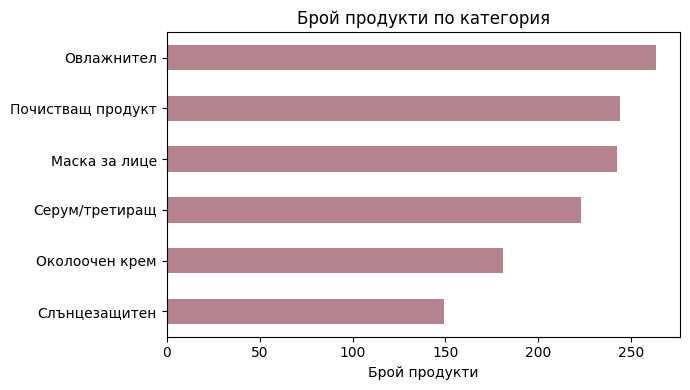


Продукти по категория:
категория
Овлажнител           263
Почистващ продукт    244
Маска за лице        242
Серум/третиращ       223
Околоочен крем       181
Слънцезащитен        149
Name: count, dtype: int64


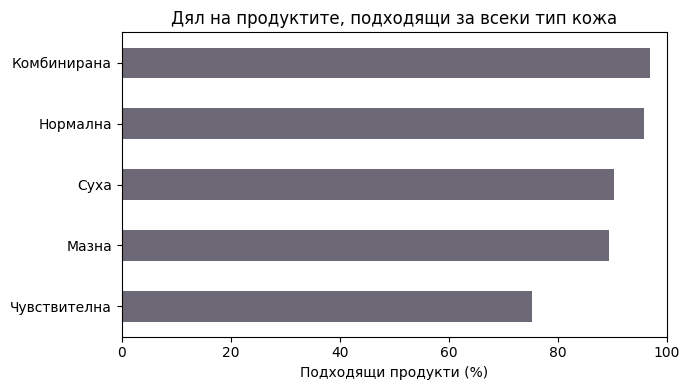


Дял подходящи продукти по тип кожа (%):
Чувствителна    75.2
Мазна           89.4
Суха            90.3
Нормална        95.7
Комбинирана     96.9
dtype: float64


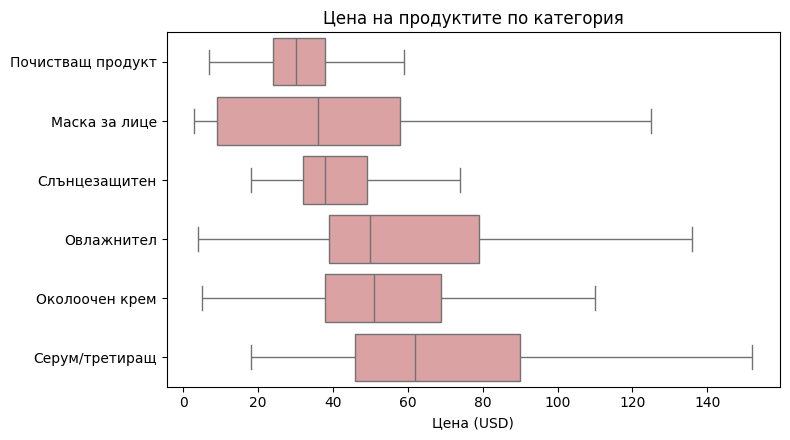


Медианна цена по категория (USD):
категория
Почистващ продукт    30.0
Маска за лице        36.0
Слънцезащитен        38.0
Овлажнител           50.0
Околоочен крем       51.0
Серум/третиращ       62.0
Name: Price, dtype: float64


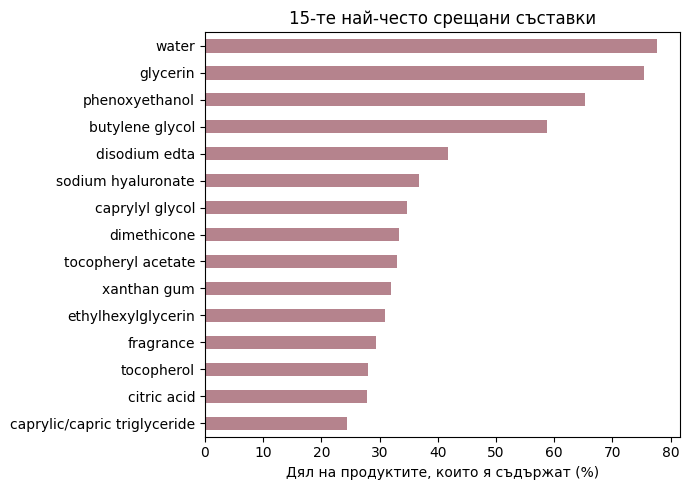


Най-чести съставки (%):
water                           77.7
glycerin                        75.5
phenoxyethanol                  65.4
butylene glycol                 58.8
disodium edta                   41.8
sodium hyaluronate              36.9
caprylyl glycol                 34.8
dimethicone                     33.3
tocopheryl acetate              32.9
xanthan gum                     32.0
ethylhexylglycerin              30.9
fragrance                       29.3
tocopherol                      28.0
citric acid                     27.8
caprylic/capric triglyceride    24.3
Name: count, dtype: float64


In [4]:
# ---------------------------------------------------------------
# 3. Анализ на данните (графики)
# ---------------------------------------------------------------
# Фигура 1: продукти по категория
plt.figure(figsize=(7, 4))
red = df["категория"].value_counts()
red.sort_values().plot(kind="barh", color="#b5838d")
plt.title("Брой продукти по категория")
plt.xlabel("Брой продукти")
plt.ylabel("")
plt.tight_layout()
plt.savefig("fig1_kategorii.png", dpi=200)
plt.show()
print("\nПродукти по категория:")
print(red)

# Фигура 2: за кои типове кожа са продуктите
s_tip = df[df["има_тип_кожа"]]
dial_tip = (s_tip[TIPOVE].mean() * 100).rename(TIPOVE_BG).sort_values()
plt.figure(figsize=(7, 4))
dial_tip.plot(kind="barh", color="#6d6875")
plt.title("Дял на продуктите, подходящи за всеки тип кожа")
plt.xlabel("Подходящи продукти (%)")
plt.xlim(0, 100)
plt.tight_layout()
plt.savefig("fig2_tip_koja.png", dpi=200)
plt.show()
print("\nДял подходящи продукти по тип кожа (%):")
print(dial_tip.round(1))

# Фигура 3: цена по категория
plt.figure(figsize=(8, 4.5))
red_k = df.groupby("категория")["Price"].median().sort_values().index
sns.boxplot(x="Price", y="категория", data=df, order=red_k, color="#e5989b",
            showfliers=False)
plt.title("Цена на продуктите по категория")
plt.xlabel("Цена (USD)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("fig3_ceni.png", dpi=200)
plt.show()
print("\nМедианна цена по категория (USD):")
print(df.groupby("категория")["Price"].median().sort_values())

# Фигура 4: най-често срещаните съставки
vsichki = pd.Series([s for spisak in df["съставки"] for s in set(spisak)])
top15 = (vsichki.value_counts().head(15) / len(df) * 100)
plt.figure(figsize=(7, 5))
top15.sort_values().plot(kind="barh", color="#b5838d")
plt.title("15-те най-често срещани съставки")
plt.xlabel("Дял на продуктите, които я съдържат (%)")
plt.tight_layout()
plt.savefig("fig4_sastavki.png", dpi=200)
plt.show()
print("\nНай-чести съставки (%):")
print(top15.round(1))

## 4. Извличане на знания: съставки и чувствителна кожа


Дял на продуктите за чувствителна кожа (%):
      съставка  дял продукти (%)  със съставката  без съставката
   niacinamide              11.6            84.9            74.0
      glycerin              80.6            76.2            71.3
phenoxyethanol              64.1            74.4            76.6
     fragrance              37.2            73.6            76.2
      linalool              21.7            68.3            77.1
      limonene              22.1            67.3            77.5
 alcohol denat               9.6            63.6            76.4
salicylic acid               7.9            61.1            76.4
       retinol               4.1            60.5            75.9


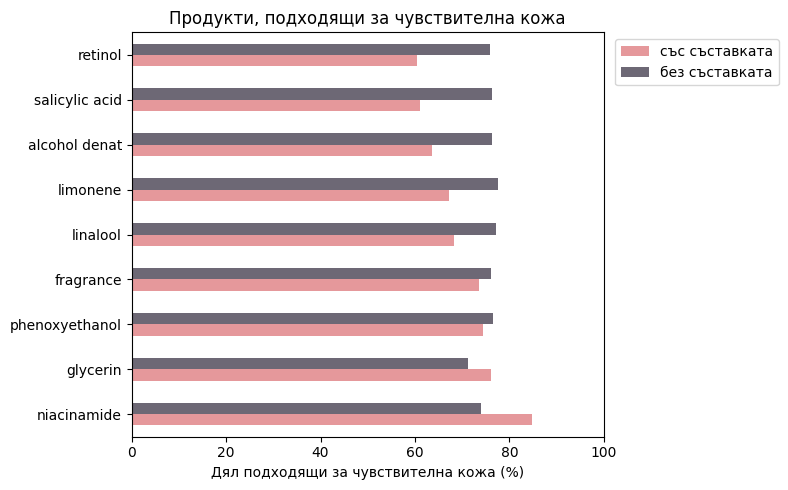

In [5]:
# ---------------------------------------------------------------
# 4. Извличане на знания: съставки и чувствителна кожа
# ---------------------------------------------------------------
izsledvani = ["niacinamide", "glycerin", "phenoxyethanol", "fragrance",
              "linalool", "limonene", "alcohol denat", "salicylic acid", "retinol"]
redove = []
for sastavka in izsledvani:
    ima = s_tip["Ingredients"].str.lower().str.contains(sastavka, regex=False)
    redove.append({"съставка": sastavka,
                   "дял продукти (%)": round(ima.mean() * 100, 1),
                   "със съставката": round(s_tip.loc[ima, "Sensitive"].mean() * 100, 1),
                   "без съставката": round(s_tip.loc[~ima, "Sensitive"].mean() * 100, 1)})
znanie = pd.DataFrame(redove)
print("\nДял на продуктите за чувствителна кожа (%):")
print(znanie.to_string(index=False))

# Фигура 5
z = znanie.set_index("съставка")[["със съставката", "без съставката"]]
z.plot(kind="barh", figsize=(8, 5), color=["#e5989b", "#6d6875"])
plt.title("Продукти, подходящи за чувствителна кожа")
plt.xlabel("Дял подходящи за чувствителна кожа (%)")
plt.ylabel("")
plt.xlim(0, 100)
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig("fig5_chuvstvitelna.png", dpi=200)
plt.show()

## 5. Представяне на продуктите с числа (TF-IDF) и сходство

In [6]:
# ---------------------------------------------------------------
# 5. Представяне на продуктите с числа (TF-IDF) и сходство
# ---------------------------------------------------------------
vektorizator = TfidfVectorizer(tokenizer=razdeli_sastavki, lowercase=False,
                               token_pattern=None, min_df=2, sublinear_tf=True)
X = vektorizator.fit_transform(df["Ingredients"])
print("\nМатрица продукти x съставки:", X.shape)

shodstvo = cosine_similarity(X)   # сходство между всеки два продукта (0 до 1)


Матрица продукти x съставки: (1302, 2610)


## 6. Карта на продуктите с t-SNE

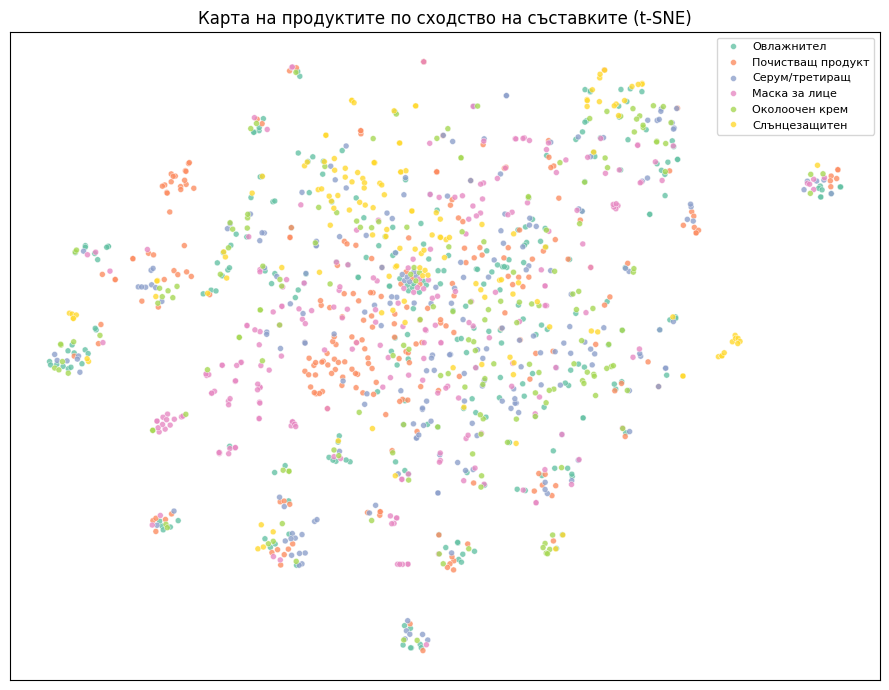

In [7]:
# ---------------------------------------------------------------
# 6. Карта на продуктите с t-SNE
# ---------------------------------------------------------------
X_50 = TruncatedSVD(n_components=50, random_state=42).fit_transform(X)
koord = TSNE(n_components=2, perplexity=30, init="pca",
             random_state=42).fit_transform(X_50)
df["x"], df["y"] = koord[:, 0], koord[:, 1]

plt.figure(figsize=(9, 7))
sns.scatterplot(x="x", y="y", hue="категория", data=df, s=18, alpha=0.8,
                palette="Set2")
plt.title("Карта на продуктите по сходство на съставките (t-SNE)")
plt.xlabel("")
plt.ylabel("")
plt.xticks([])
plt.yticks([])
plt.legend(title="", loc="best", fontsize=8)
plt.tight_layout()
plt.savefig("fig6_karta_tsne.png", dpi=200)
plt.show()

## 7. Препоръчваща система


Избран продукт: LA MER - Crème de la Mer, 175 USD, рейтинг 4.1
По-евтини сходни продукти за суха кожа:
   Brand                                                         Name  Price  Rank  сходство
  LA MER                                         Crème de la Mer Mini     85   4.1     1.000
  LA MER                                         The Renewal Oil Mini    130   4.0     0.332
CLINIQUE                  Dramatically Different Moisturizing Lotion+     28   3.9     0.137
CLINIQUE Limited Edition Dramatically Different Moisturizing Lotion+™     39   0.0     0.137
GLAMGLOW                   DREAMDUO™ Overnight Transforming Treatment     59   4.2     0.099


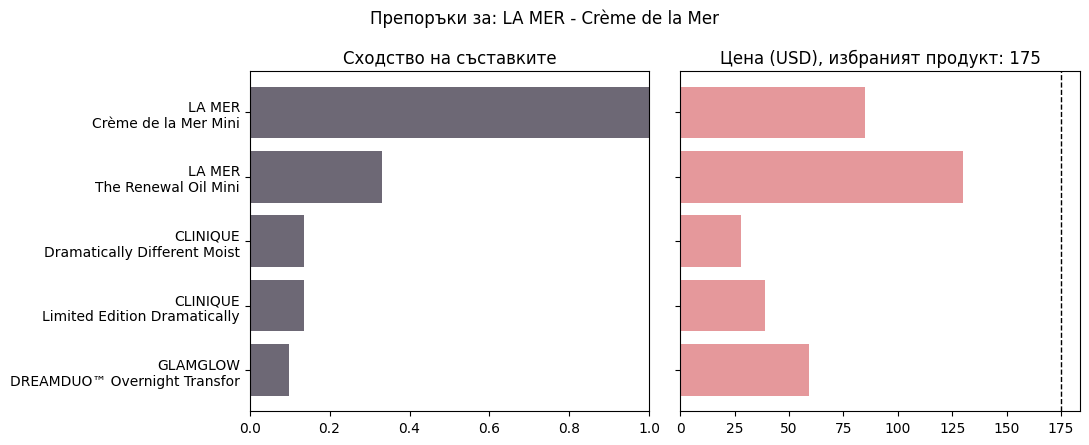

In [8]:
# ---------------------------------------------------------------
# 7. Препоръчваща система
# ---------------------------------------------------------------
def preporachai(ime, tip_koja=None, po_evtini=False, n=5):
    """Връща n продукта от същата категория с най-сходни съставки."""
    i = df.index[df["Name"] == ime][0]
    kandidati = df[(df["Label"] == df.loc[i, "Label"]) & (df.index != i)].copy()
    if tip_koja:
        kandidati = kandidati[kandidati[tip_koja] == 1]
    if po_evtini:
        kandidati = kandidati[kandidati["Price"] < df.loc[i, "Price"]]
    kandidati["сходство"] = shodstvo[i, kandidati.index]
    return kandidati.sort_values("сходство", ascending=False).head(n)[
        ["Brand", "Name", "Price", "Rank", "сходство"]]

# Пример: известен скъп овлажнител -> по-евтини сходни продукти за суха кожа
primer = df[df["Name"] == "Crème de la Mer"].iloc[0]
print(f"\nИзбран продукт: {primer['Brand']} - {primer['Name']}, "
      f"{primer['Price']} USD, рейтинг {primer['Rank']}")
preporaki = preporachai(primer["Name"], tip_koja="Dry", po_evtini=True)
print("По-евтини сходни продукти за суха кожа:")
print(preporaki.round(3).to_string(index=False))
preporaki.to_csv("primer_preporaki.csv", index=False, encoding="utf-8-sig")

# Фигура 7: примерът
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
etiketi = [f"{b}\n{n[:28]}" for b, n in zip(preporaki["Brand"], preporaki["Name"])]
ax[0].barh(etiketi[::-1], preporaki["сходство"][::-1], color="#6d6875")
ax[0].set_title("Сходство на съставките")
ax[0].set_xlim(0, 1)
ax[1].barh(etiketi[::-1], preporaki["Price"][::-1], color="#e5989b")
ax[1].axvline(primer["Price"], color="black", ls="--", lw=1)
ax[1].set_title(f"Цена (USD), избраният продукт: {primer['Price']}")
plt.suptitle(f"Препоръки за: {primer['Brand']} - {primer['Name'][:40]}")
plt.tight_layout()
plt.savefig("fig7_primer.png", dpi=200)
plt.show()

## 8. Оценка на препоръките


Оценка: дял препоръки от същата категория (точност@5):
                       Метод  Точност@5
TF-IDF + косинусово сходство      0.367
          Жакаров коефициент      0.364
               Случаен избор      0.172

Точност@5 по категория (%):
категория
Околоочен крем       28.2
Овлажнител           28.9
Серум/третиращ       29.7
Почистващ продукт    42.5
Слънцезащитен        45.1
Маска за лице        46.9
Name: съвпадения, dtype: float64


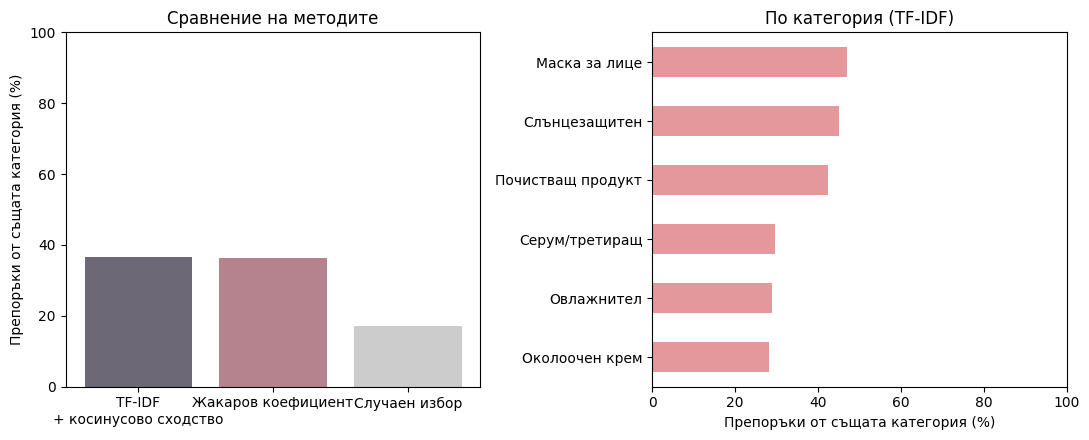


Готово! Графиките са записани като PNG файлове.


In [9]:
# ---------------------------------------------------------------
# 8. Оценка на препоръките
#    Проверяваме: от 5-те най-сходни продукта (без филтър по категория)
#    колко са от същата категория? Сравняваме с два метода и случаен избор.
# ---------------------------------------------------------------
kat = df["Label"].to_numpy(dtype=object)

def tochnost_pri_k(S, k=5):
    S = S.copy()
    np.fill_diagonal(S, -1)
    nai_blizki = np.argsort(-S, axis=1)[:, :k]
    return (kat[nai_blizki] == kat[:, None]).mean()

dvoichna = CountVectorizer(tokenizer=razdeli_sastavki, lowercase=False,
                           token_pattern=None, min_df=2, binary=True)
B = dvoichna.fit_transform(df["Ingredients"]).toarray().astype(bool)
shodstvo_jaccard = 1 - pairwise_distances(B, metric="jaccard")

rng = np.random.default_rng(42)
sluchaen = np.mean([(kat[rng.choice(len(kat), 5, replace=False)] == k).mean()
                    for k in kat])

ocenka = pd.DataFrame({
    "Метод": ["TF-IDF + косинусово сходство", "Жакаров коефициент", "Случаен избор"],
    "Точност@5": [round(tochnost_pri_k(shodstvo), 3),
                  round(tochnost_pri_k(shodstvo_jaccard), 3),
                  round(sluchaen, 3)]})
print("\nОценка: дял препоръки от същата категория (точност@5):")
print(ocenka.to_string(index=False))
ocenka.to_csv("tablica_ocenka.csv", index=False, encoding="utf-8-sig")

# Точност@5 по категории за основния метод
S = shodstvo.copy()
np.fill_diagonal(S, -1)
nb = np.argsort(-S, axis=1)[:, :5]
df["съвпадения"] = (kat[nb] == kat[:, None]).mean(axis=1)
po_kat = (df.groupby("категория")["съвпадения"].mean() * 100).sort_values()
print("\nТочност@5 по категория (%):")
print(po_kat.round(1))

# Фигура 8
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].bar(ocenka["Метод"].str.replace(" + ", "\n+ ", regex=False),
          ocenka["Точност@5"] * 100, color=["#6d6875", "#b5838d", "#cccccc"])
ax[0].set_ylabel("Препоръки от същата категория (%)")
ax[0].set_title("Сравнение на методите")
ax[0].set_ylim(0, 100)
po_kat.plot(kind="barh", ax=ax[1], color="#e5989b")
ax[1].set_title("По категория (TF-IDF)")
ax[1].set_xlabel("Препоръки от същата категория (%)")
ax[1].set_ylabel("")
ax[1].set_xlim(0, 100)
plt.tight_layout()
plt.savefig("fig8_ocenka.png", dpi=200)
plt.show()

print("\nГотово! Графиките са записани като PNG файлове.")